import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import re

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


Load dataset

In [2]:
file_path = "/content/dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (4920, 18)


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Understand the dataset

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for column in df.columns:
    print(column)

print("\nDataset information:")
df.info()

Number of rows: 4920
Number of columns: 18

Column names:
Disease
Symptom_1
Symptom_2
Symptom_3
Symptom_4
Symptom_5
Symptom_6
Symptom_7
Symptom_8
Symptom_9
Symptom_10
Symptom_11
Symptom_12
Symptom_13
Symptom_14
Symptom_15
Symptom_16
Symptom_17

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Disease     4920 non-null   object
 1   Symptom_1   4920 non-null   object
 2   Symptom_2   4920 non-null   object
 3   Symptom_3   4920 non-null   object
 4   Symptom_4   4572 non-null   object
 5   Symptom_5   3714 non-null   object
 6   Symptom_6   2934 non-null   object
 7   Symptom_7   2268 non-null   object
 8   Symptom_8   1944 non-null   object
 9   Symptom_9   1692 non-null   object
 10  Symptom_10  1512 non-null   object
 11  Symptom_11  1194 non-null   object
 12  Symptom_12  744 non-null    object
 13  Symptom_13  504 non-nu

Check diseases

In [4]:
print("Number of unique diseases:", df["Disease"].nunique())

print("\nDisease classes:")

for i, disease in enumerate(sorted(df["Disease"].unique()), start=1):
    print(f"{i}. {disease}")

Number of unique diseases: 41

Disease classes:
1. (vertigo) Paroymsal  Positional Vertigo
2. AIDS
3. Acne
4. Alcoholic hepatitis
5. Allergy
6. Arthritis
7. Bronchial Asthma
8. Cervical spondylosis
9. Chicken pox
10. Chronic cholestasis
11. Common Cold
12. Dengue
13. Diabetes 
14. Dimorphic hemmorhoids(piles)
15. Drug Reaction
16. Fungal infection
17. GERD
18. Gastroenteritis
19. Heart attack
20. Hepatitis B
21. Hepatitis C
22. Hepatitis D
23. Hepatitis E
24. Hypertension 
25. Hyperthyroidism
26. Hypoglycemia
27. Hypothyroidism
28. Impetigo
29. Jaundice
30. Malaria
31. Migraine
32. Osteoarthristis
33. Paralysis (brain hemorrhage)
34. Peptic ulcer diseae
35. Pneumonia
36. Psoriasis
37. Tuberculosis
38. Typhoid
39. Urinary tract infection
40. Varicose veins
41. hepatitis A


Check missing values

In [5]:
print("Missing values:")
display(df.isnull().sum())

Missing values:


,0
Disease,0
Symptom_1,0
Symptom_2,0
Symptom_3,0
Symptom_4,348
Symptom_5,1206
Symptom_6,1986
Symptom_7,2652
Symptom_8,2976
Symptom_9,3228


Clean the symptom names

In [6]:
df["Disease"] = df["Disease"].astype(str).str.strip()

symptom_columns = [col for col in df.columns if col.startswith("Symptom_")]

for col in symptom_columns:
    df[col] = df[col].fillna("").astype(str).str.strip()
    df[col] = df[col].str.lower()

print("Symptom names cleaned successfully!")

display(df.head())

Symptom names cleaned successfully!


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,,,,,,,,,,,,,
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,,,,,,,,,,,,,,
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,,,,,,,,,,,,,,
3,Fungal infection,itching,skin_rash,dischromic _patches,,,,,,,,,,,,,,
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,,,,,,,,,,,,,,


Remove completely empty symptom entries

In [7]:
df = df[
    df[symptom_columns]
    .replace("", np.nan)
    .notna()
    .any(axis=1)
].copy()

print("Shape after removing empty symptom records:", df.shape)

Shape after removing empty symptom records: (4920, 18)


Remove duplicate records

In [8]:
before_duplicates = len(df)

df = df.drop_duplicates().reset_index(drop=True)

after_duplicates = len(df)

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Rows before removing duplicates: 4920
Rows after removing duplicates: 304
Duplicates removed: 4616


Create a clean symptom list

In [9]:
all_symptoms = set()

for col in symptom_columns:
    for symptom in df[col]:
        if symptom.strip() != "":
            all_symptoms.add(symptom.strip())

all_symptoms = sorted(all_symptoms)

print("Total unique symptoms:", len(all_symptoms))

print("\nFirst 30 symptoms:")
for symptom in all_symptoms[:30]:
    print(symptom)

Total unique symptoms: 131

First 30 symptoms:
abdominal_pain
abnormal_menstruation
acidity
acute_liver_failure
altered_sensorium
anxiety
back_pain
belly_pain
blackheads
bladder_discomfort
blister
blood_in_sputum
bloody_stool
blurred_and_distorted_vision
breathlessness
brittle_nails
bruising
burning_micturition
chest_pain
chills
cold_hands_and_feets
coma
congestion
constipation
continuous_feel_of_urine
continuous_sneezing
cough
cramps
dark_urine
dehydration


Convert symptoms into numerical features

In [10]:
X = pd.DataFrame(
    0,
    index=df.index,
    columns=all_symptoms
)

for index, row in df.iterrows():

    for col in symptom_columns:

        symptom = row[col].strip()

        if symptom != "":
            X.loc[index, symptom] = 1

print("Feature matrix created!")
print("X shape:", X.shape)

display(X.head())

Feature matrix created!
X shape: (304, 131)


,abdominal_pain,abnormal_menstruation,acidity,acute_liver_failure,altered_sensorium,anxiety,back_pain,belly_pain,blackheads,bladder_discomfort,...,vomiting,watering_from_eyes,weakness_in_limbs,weakness_of_one_body_side,weight_gain,weight_loss,yellow_crust_ooze,yellow_urine,yellowing_of_eyes,yellowish_skin
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Create target variable

In [11]:
y = df["Disease"]

print("Target shape:", y.shape)

print("\nDisease distribution:")
print(y.value_counts())

Target shape: (304,)

Disease distribution:
Disease
Migraine                                   10
Dengue                                     10
Hepatitis D                                10
Chicken pox                                10
Typhoid                                     9
Hepatitis B                                 9
Jaundice                                    9
hepatitis A                                 9
Diabetes                                    9
Hepatitis E                                 9
Pneumonia                                   9
Common Cold                                 9
Hypoglycemia                                9
Hyperthyroidism                             9
Tuberculosis                                9
Alcoholic hepatitis                         8
Chronic cholestasis                         8
Varicose veins                              8
Hypothyroidism                              8
Malaria                                     8
(vertigo) Paroymsal  Positio

Encode disease names

In [12]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Disease encoding completed!")

print("\nExample encoding:")

for i in range(min(10, len(label_encoder.classes_))):
    print(
        label_encoder.classes_[i],
        "->",
        i
    )

Disease encoding completed!

Example encoding:
(vertigo) Paroymsal  Positional Vertigo -> 0
AIDS -> 1
Acne -> 2
Alcoholic hepatitis -> 3
Allergy -> 4
Arthritis -> 5
Bronchial Asthma -> 6
Cervical spondylosis -> 7
Chicken pox -> 8
Chronic cholestasis -> 9


Train/test split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 243
Testing samples: 61
Number of features: 131


Train Decision Tree

In [14]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=None
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 65.57 %


Train Random Forest

In [15]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 100.0 %


Train Extra Trees

In [16]:
et_model = ExtraTreesClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

et_model.fit(X_train, y_train)

et_predictions = et_model.predict(X_test)

et_accuracy = accuracy_score(
    y_test,
    et_predictions
)

print("Extra Trees Accuracy:",
      round(et_accuracy * 100, 2), "%")

Extra Trees Accuracy: 100.0 %


Train KNN

In [17]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train, y_train)

knn_predictions = knn_model.predict(X_test)

knn_accuracy = accuracy_score(
    y_test,
    knn_predictions
)

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 100.0 %


Compare all models

In [18]:
model_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Extra Trees",
        "KNN"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy,
        et_accuracy,
        knn_accuracy
    ]
})

model_results["Accuracy (%)"] = (
    model_results["Accuracy"] * 100
).round(2)

display(
    model_results[
        ["Model", "Accuracy (%)"]
    ].sort_values(
        "Accuracy (%)",
        ascending=False
    )
)

,Model,Accuracy (%)
1,Random Forest,100.00
2,Extra Trees,100.00
3,KNN,100.00
0,Decision Tree,65.57


Automatically select the best model

In [19]:
models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Extra Trees": et_model,
    "KNN": knn_model
}

accuracies = {
    "Decision Tree": dt_accuracy,
    "Random Forest": rf_accuracy,
    "Extra Trees": et_accuracy,
    "KNN": knn_accuracy
}

best_model_name = max(
    accuracies,
    key=accuracies.get
)

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print(
    "Best Accuracy:",
    round(accuracies[best_model_name] * 100, 2),
    "%"
)

Best Model: Random Forest
Best Accuracy: 100.0 %


Detailed evaluation

In [20]:
best_predictions = best_model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    best_predictions
)

precision = precision_score(
    y_test,
    best_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    best_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    best_predictions,
    average="weighted",
    zero_division=0
)

print("====================================")
print("MODEL EVALUATION")
print("====================================")

print(f"Model      : {best_model_name}")
print(f"Accuracy   : {accuracy * 100:.2f}%")
print(f"Precision  : {precision * 100:.2f}%")
print(f"Recall     : {recall * 100:.2f}%")
print(f"F1 Score   : {f1 * 100:.2f}%")

MODEL EVALUATION
Model      : Random Forest
Accuracy   : 100.00%
Precision  : 100.00%
Recall     : 100.00%
F1 Score   : 100.00%


Classification report

In [21]:
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                                         precision    recall  f1-score   support

(vertigo) Paroymsal  Positional Vertigo       1.00      1.00      1.00         1
                                   AIDS       1.00      1.00      1.00         1
                                   Acne       1.00      1.00      1.00         1
                    Alcoholic hepatitis       1.00      1.00      1.00         2
                                Allergy       1.00      1.00      1.00         1
                              Arthritis       1.00      1.00      1.00         1
                       Bronchial Asthma       1.00      1.00      1.00         1
                   Cervical spondylosis       1.00      1.00      1.00         1
                            Chicken pox       1.00      1.00      1.00         2
                    Chronic cholestasis       1.00      1.00      1.00         2
                            Common Cold       1.00      1.00      1.00         2
                           

Confusion matrix

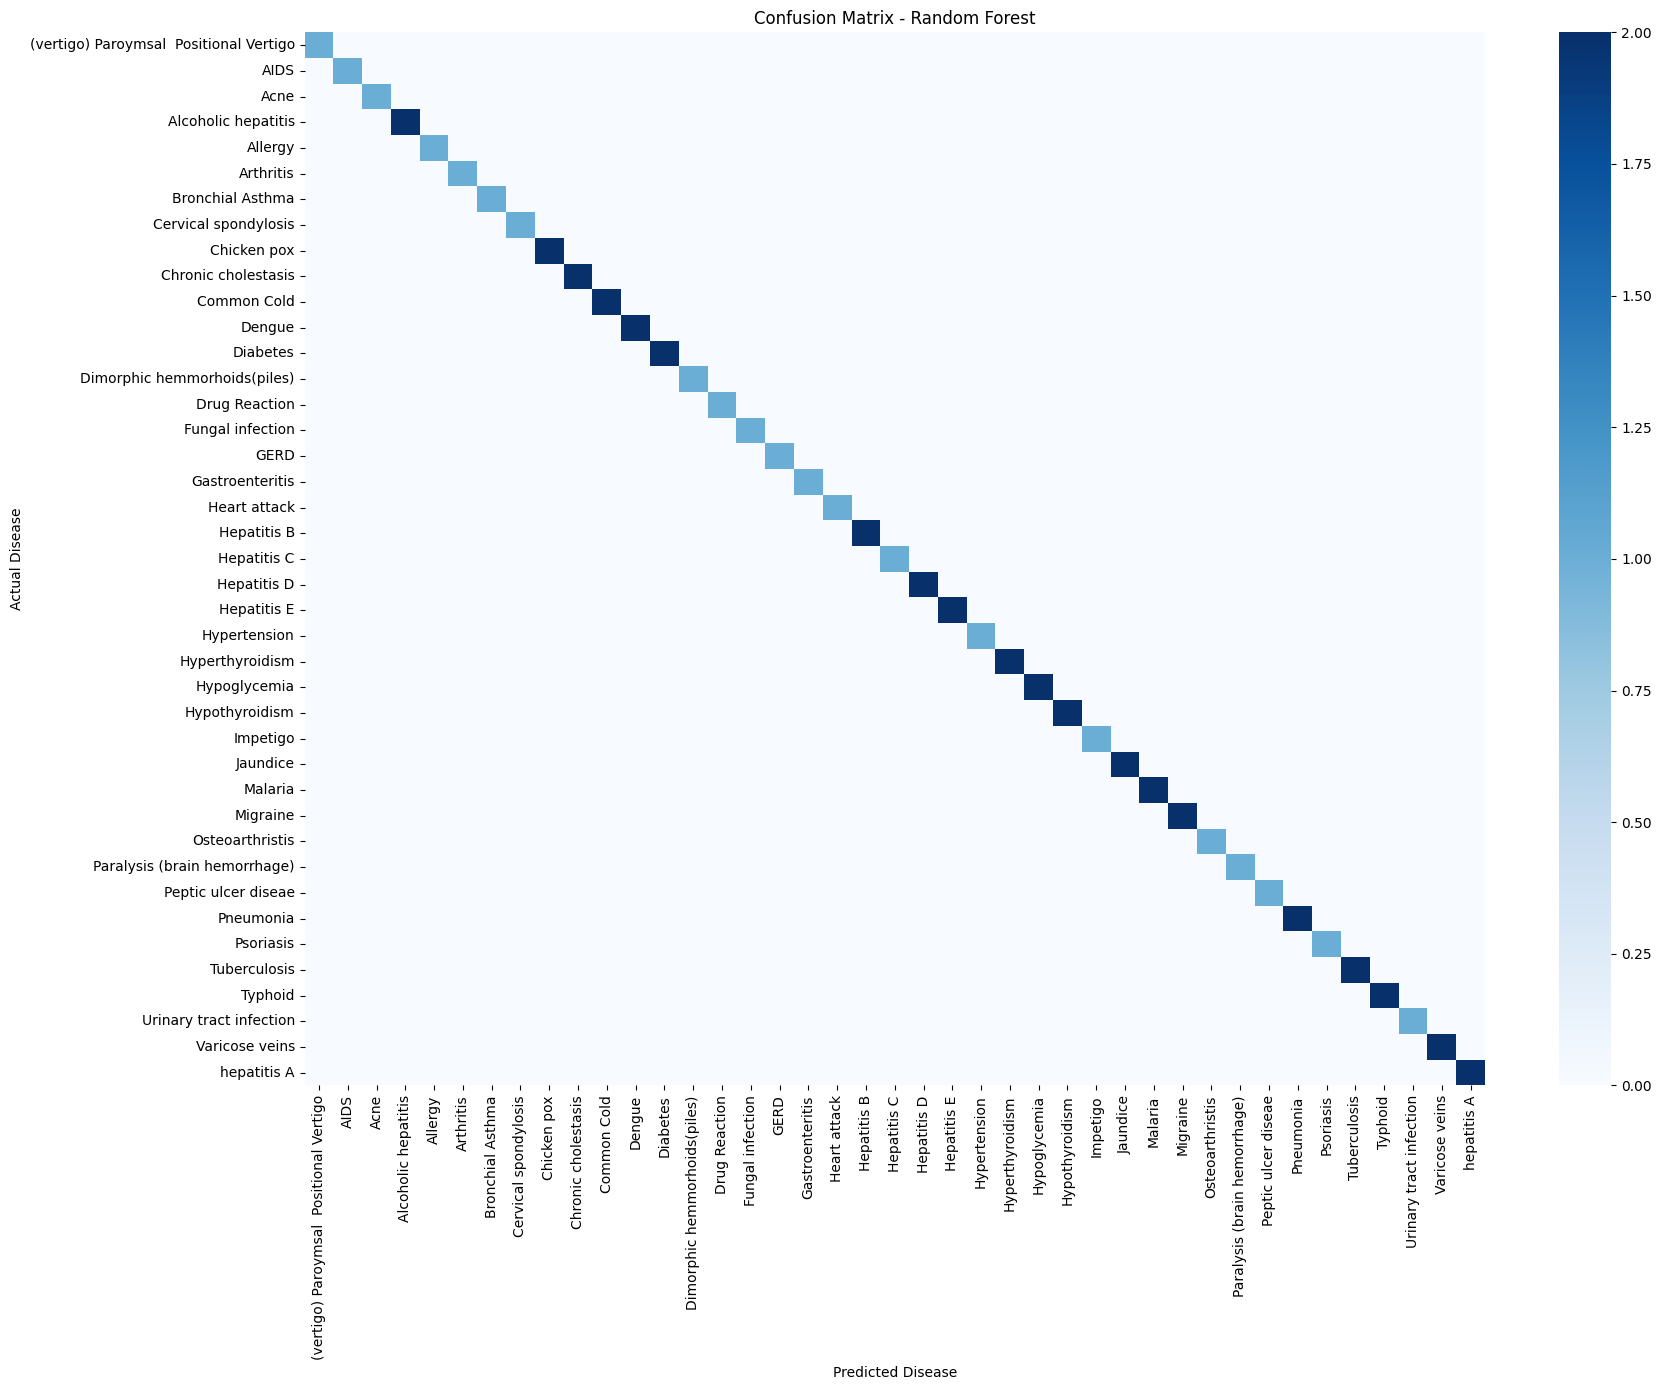

In [22]:
cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(18, 14))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

Model comparison graph

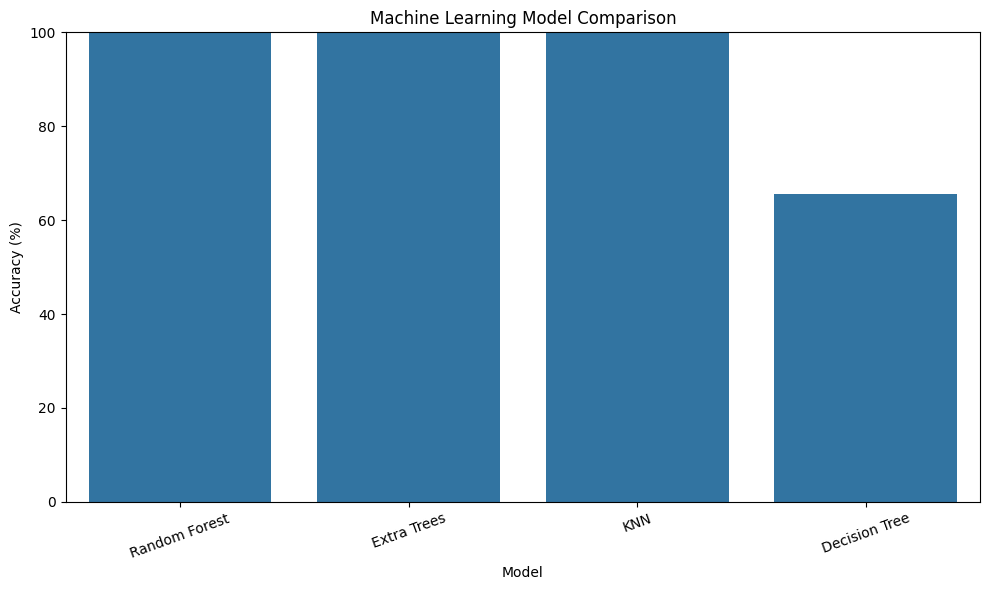

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_results.sort_values(
        "Accuracy (%)",
        ascending=False
    ),
    x="Model",
    y="Accuracy (%)"
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

Test the model with symptoms

In [24]:
def predict_disease(symptoms):
    """
    Predict possible disease based on a list of symptoms.
    """

    # Create empty feature vector
    input_data = pd.DataFrame(
        0,
        index=[0],
        columns=all_symptoms
    )

    # Add user symptoms
    for symptom in symptoms:

        symptom = symptom.strip().lower()

        if symptom in input_data.columns:
            input_data.loc[0, symptom] = 1

    # Prediction
    prediction = best_model.predict(input_data)[0]

    # Convert number back to disease name
    disease = label_encoder.inverse_transform(
        [prediction]
    )[0]

    # Confidence if model supports probabilities
    confidence = None

    if hasattr(best_model, "predict_proba"):

        probabilities = best_model.predict_proba(
            input_data
        )[0]

        confidence = np.max(probabilities)

    return disease, confidence

Test prediction

In [25]:
test_symptoms = [
    "itching",
    "skin_rash",
    "nodal_skin_eruptions"
]

disease, confidence = predict_disease(
    test_symptoms
)

print("Input symptoms:")
print(test_symptoms)

print("\nPredicted condition:")
print(disease)

if confidence is not None:
    print(
        "\nModel confidence:",
        round(confidence * 100, 2),
        "%"
    )

Input symptoms:
['itching', 'skin_rash', 'nodal_skin_eruptions']

Predicted condition:
Fungal infection

Model confidence: 78.33 %


In [26]:
test_symptoms = [
    "continuous_sneezing",
    "shivering",
    "chills"
]

disease, confidence = predict_disease(
    test_symptoms
)

print("Symptoms:", test_symptoms)
print("Predicted condition:", disease)

if confidence is not None:
    print(
        "Model confidence:",
        round(confidence * 100, 2),
        "%"
    )

Symptoms: ['continuous_sneezing', 'shivering', 'chills']
Predicted condition: Allergy
Model confidence: 86.33 %


Save the trained model

In [27]:

os.makedirs("/content/model", exist_ok=True)
joblib.dump(
    best_model,
    "/content/model/disease_model.pkl"
)

joblib.dump(
    label_encoder,
    "/content/model/label_encoder.pkl"
)

joblib.dump(
    all_symptoms,
    "/content/model/symptom_features.pkl"
)

print("Models saved successfully!")

Models saved successfully!
